# Figure 5 · Isolated galaxy, pairs and crowded fields

**Five selected validation fields.** Columns: NISP Y, JWST, bilinear,
diffusion, ResNet, ResNet-D5 (direct-5× variant). Row **a** restores the
modest isolated galaxy previously shown in v04 row c. Rows **b–e** retain
v05 rows a–d in order: a close projected pair, the face-on disk, overlapping
elongated sources and the crowded field. The former v05 row e is omitted.
All objects retain their prior display scales and diffusion seeds.

This is an editorial rearrangement of previously viewed examples, with a
simple isolated source added at the user's request. The original selections
were based on observed NISP/JWST images before their first prediction exports.
The pairs/crowded fields came from an observation-only search of validation
crops ranked by the second-brightest separated JWST peak; 64 spatially distinct
candidates were reviewed. The isolated source came from the earlier seeded
40-object pool. Selection provenance and source rows are recorded in the
selection metadata. These examples illustrate morphology and source multiplicity,
not population statistics or a model ranking. Projected neighbors need not be
physically associated.

The exporter snapshots best checkpoints in tmux with online W&B. This notebook
only reads saved arrays. Bilinear retains NISP's band and instrumental response.
For future updates retain `inputs/galaxy_examples_selection_v06.json`, set matching new
`VERSION` and `BUNDLE_VERSION` values for a prediction update and pass that selection with `--selection` to the exporter. This preserves
IDs, per-row display limits and diffusion noise seeds. The three-sample diffusion
mean remains available as an optional prediction column.


Style revision v08: shared scientific figure style, Matisse-inspired method
colors with redundant line patterns and redundant symbols. Frozen inputs, populations, and numerical values
are retained; the previous executed notebook is archived in `revisions/style_before_v01/`.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v08'
BUNDLE_VERSION = 'v06'  # Display-label revision; reuse frozen predictions.
N_EXAMPLES = 5
PREDICTIONS = ['diffusion', 'legacy', 'direct5']
CROP_NATIVE = 21  # Set to 41 for the full field; odd widths preserve grid alignment.
assert CROP_NATIVE in (21, 41)
bundle_path = FIGURES / 'inputs' / f'galaxy_examples_{BUNDLE_VERSION}.npz'
metadata_path = bundle_path.with_suffix('.json')
ready = bundle_path.exists() and metadata_path.exists()

from figure_utils import MARKERS, INK, GRID, ESTIMATOR_COLORS, finish_axes


In [2]:
if not ready:
    display(Markdown('**Waiting for the versioned prediction bundle.** Export with `code/export_paper_examples.py` inside tmux with online W&B.'))
else:
    metadata = read_json(metadata_path)
    assert metadata['complete'] and metadata['split'] == 'validation'
    assert metadata['units'] == 'MJy/sr' and metadata['npz_sha256'] == sha(bundle_path)
    with np.load(bundle_path, allow_pickle=False) as saved:
        images = dict(saved)
    ids = images['object_ids']
    assert len(np.unique(ids)) == len(ids)
    np.testing.assert_array_equal(ids, metadata['object_ids'])
    assert images['nisp'].shape == images['nisp_valid'].shape == (len(ids), 41, 41)
    assert images['jwst'].shape == images['jwst_valid'].shape == (len(ids), 205, 205)
    for name in PREDICTIONS:
        assert images[name].shape == images['jwst'].shape and metadata['checkpoint_sha256'][name]
    display(pd.DataFrame(metadata['checkpoints']).T[['epoch', 'criterion', 'training_complete']])
    print('Frozen IDs:', ids.tolist())
    print(metadata['selection']['rule'])
    print('W&B:', metadata['wandb_url'])


,epoch,criterion,training_complete
legacy,49,validation/mae,True
direct5,49,validation/mae,True
diffusion,35,generated/mae_mjy_sr,True


Frozen IDs: [504234, 749105, 677525, 592591, 744769]
At user request, replace v05 row e with the modest isolated galaxy previously shown in v04 row c, and move it to the top. Follow with v05 rows a-d in their existing relative order. Existing examples and all display scales are reused; this is an illustrative editorial selection, not a new blind selection or population/performance sample. Original selections were based on observed images.
W&B: https://wandb.ai/AI-Astro/superNISP-corrected/runs/1kwf3s0z


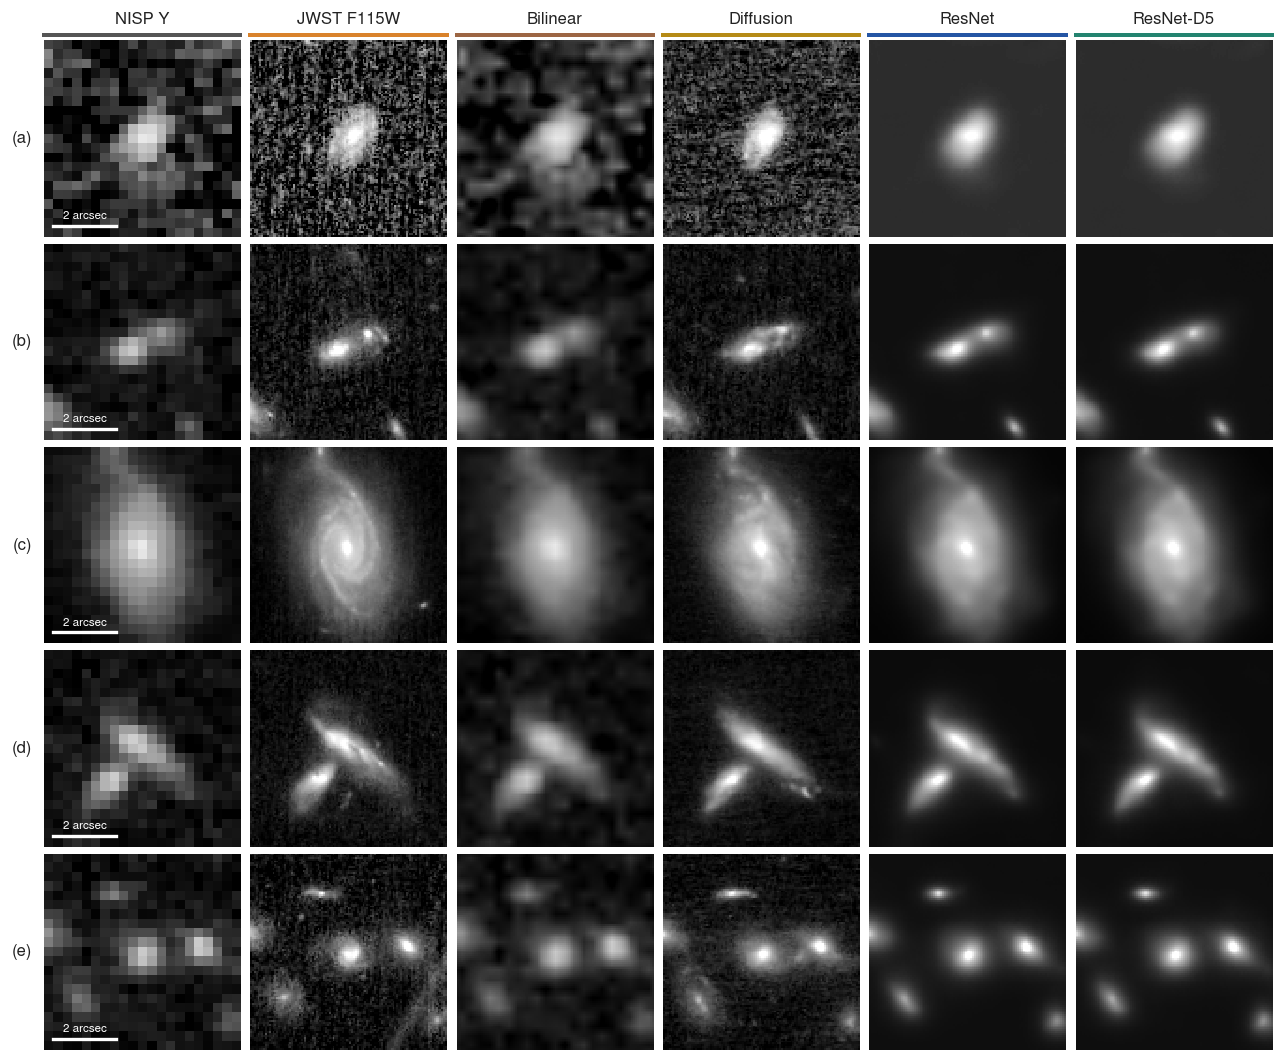

Exported: fig05_galaxy_examples_v08.pdf, fig05_galaxy_examples_v08.svg, fig05_galaxy_examples_v08.png


In [3]:
if ready:
    count = min(N_EXAMPLES, len(ids))
    names = ['nisp', 'jwst', 'bilinear', *PREDICTIONS]
    labels = {'nisp':'NISP Y', 'bilinear':'Bilinear', 'jwst':'JWST F115W', 'legacy':'ResNet',
              'direct5':'ResNet-D5', 'diffusion':'Diffusion', 'diffusion_mean3':'Diffusion mean (3)'}
    fig, axes = plt.subplots(count, len(names), figsize=(10.8, 1.8*count), squeeze=False)
    cmap = plt.get_cmap('gray').copy(); cmap.set_bad('#888888')
    native_edge = (41-CROP_NATIVE)//2
    native_slice = slice(native_edge, native_edge+CROP_NATIVE)
    target_slice = slice(5*native_edge, 5*(native_edge+CROP_NATIVE))
    for i in range(count):
        limit = metadata['limits_mjy_sr'][i]
        scale = metadata['nisp_pixel_scale_arcsec'][i]
        half_width = CROP_NATIVE*scale/2
        extent = [-half_width, half_width, -half_width, half_width]
        for j, name in enumerate(names):
            mask = images[name+'_valid'][i].astype(bool) if name in ('nisp','bilinear') else images['jwst_valid'][i].astype(bool)
            crop = native_slice if name == 'nisp' else target_slice
            values = np.ma.array(images[name][i][crop,crop], mask=~mask[crop,crop])
            axes[i,j].imshow(np.arcsinh(values/limit['stretch']), origin='lower', extent=extent,
                interpolation='nearest', cmap=cmap, vmin=np.arcsinh(limit['low']/limit['stretch']),
                vmax=np.arcsinh(limit['high']/limit['stretch']))
            axes[i,j].set_xticks([]); axes[i,j].set_yticks([])
            for spine in axes[i,j].spines.values(): spine.set_visible(False)
            if i == 0:
                axes[i,j].set_title(labels[name], fontsize=10, pad=10)
                axes[i,j].plot([0,1],[1.025,1.025],transform=axes[i,j].transAxes,
                               color=COLORS['native' if name=='nisp' else name],lw=2.4,clip_on=False)
        axes[i,0].set_ylabel(f'({chr(97+i)})', rotation=0, labelpad=13, va='center', fontsize=10)
        left, bottom = -half_width+.3, -half_width+.35
        axes[i,0].plot([left,left+2],[bottom,bottom],color='white',lw=2)
        axes[i,0].text(left+1,bottom+.16,'2 arcsec',color='white',ha='center',va='bottom',fontsize=7)
    fig.subplots_adjust(left=.045,right=.995,bottom=.015,top=.95,wspace=.035,hspace=.035)
    plt.show()
    paths = export(fig, f'fig05_galaxy_examples_{VERSION}', '05_galaxy_examples.ipynb',
        [bundle_path, metadata_path, ROOT/metadata['selection_file']],
        dict(object_ids=ids[:count].tolist(), predictions=PREDICTIONS, crop_native=CROP_NATIVE,
             intensity_limits=metadata['limits_mjy_sr'], checkpoints=metadata['checkpoints'],
             scale='fixed shared per-object asinh intensity; native NISP pixels, no display smoothing'),
        status='Provisional best-checkpoint validation examples; diffusion best available at export')


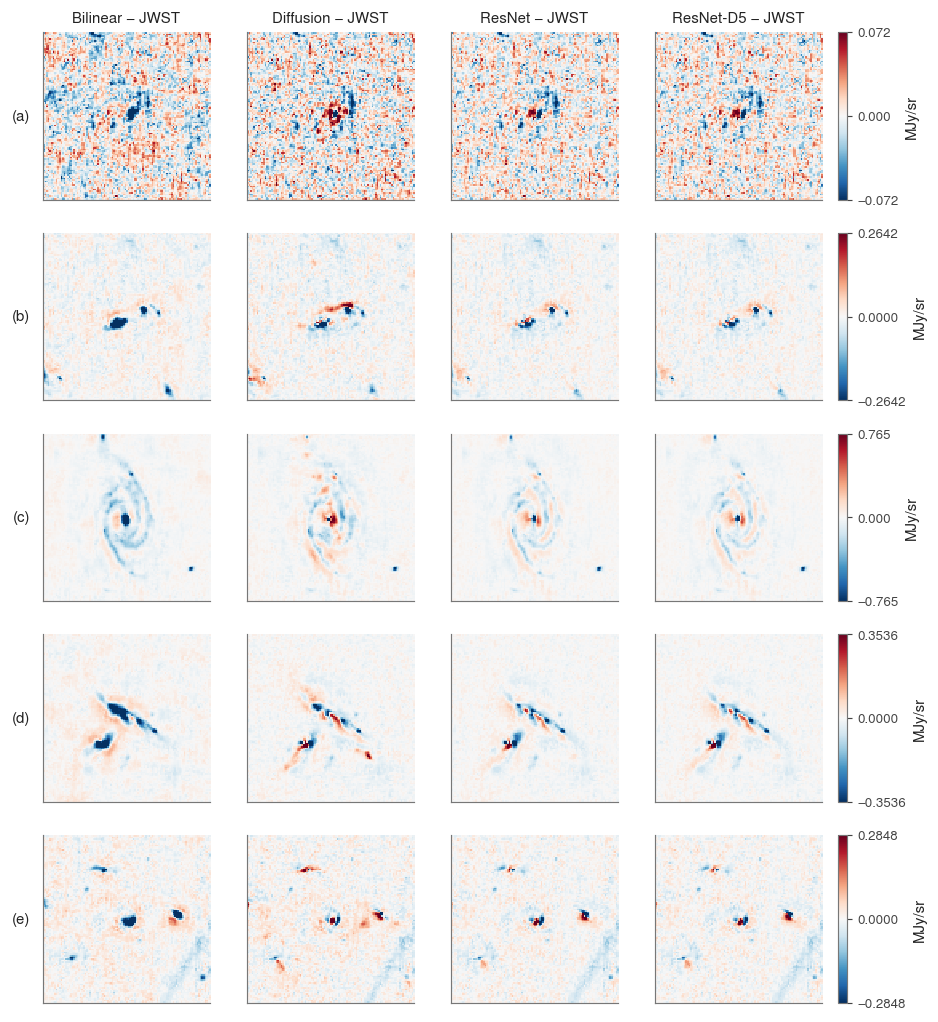

Exported: fig05_galaxy_residuals_v08.pdf, fig05_galaxy_residuals_v08.svg, fig05_galaxy_residuals_v08.png


In [4]:
# Companion residual sheet for reviewing errors; no extra model inference.
if ready:
    residual_names = ['bilinear', *PREDICTIONS]
    residual_fig, residual_axes = plt.subplots(count, len(residual_names),
        figsize=(8.8, 2.1*count), squeeze=False)
    cmap = plt.get_cmap('RdBu_r').copy(); cmap.set_bad('#888888')
    for i in range(count):
        limit = metadata['limits_mjy_sr'][i]['residual']
        mask = images['jwst_valid'][i][target_slice,target_slice].astype(bool)
        for j,name in enumerate(residual_names):
            delta = (images[name][i]-images['jwst'][i])[target_slice,target_slice]
            support = mask & images['bilinear_valid'][i][target_slice,target_slice] if name=='bilinear' else mask
            arr = np.ma.array(delta,mask=~support)
            ax=residual_axes[i,j]
            shown=ax.imshow(arr,origin='lower',interpolation='nearest',cmap=cmap,vmin=-limit,vmax=limit)
            ax.set_xticks([]); ax.set_yticks([])
            if i==0: ax.set_title(labels[name]+' − JWST',fontsize=9)
            if j==0: ax.set_ylabel(f'({chr(97+i)})',rotation=0,labelpad=13,va='center')
        residual_fig.colorbar(shown,ax=list(residual_axes[i]),fraction=.025,pad=.02,
                             label='MJy/sr',ticks=[-limit,0,limit])
    plt.show()
    residual_paths = export(residual_fig, f'fig05_galaxy_residuals_{VERSION}', '05_galaxy_examples.ipynb',
        [bundle_path, metadata_path], dict(predictions=residual_names, crop_native=CROP_NATIVE,
        residual_limits=[x['residual'] for x in metadata['limits_mjy_sr']]),
        status='Companion residual review sheet; same objects, checkpoints and crops as Figure 5')


## Working caption

Selected validation fields illustrating (a) a modest isolated galaxy, (b) a close
projected pair, (c) a face-on disk, (d) overlapping extended sources and (e) a
crowded field with multiple neighbors. Columns show NISP Y, JWST F115W, bilinear
interpolation of NISP, diffusion, ResNet and ResNet-D5 reconstructions. The
original examples were selected from observed images before their first model
prediction exports; this revision rearranges previously viewed examples and
restores an isolated source. This illustrative selection is not statistically
representative; neighboring sources are not necessarily physically associated.
Each row uses one shared intensity stretch over a roughly 6.3-arcsec field;
scale bars indicate 2 arcsec. Diffusion shows one realization from its best
available checkpoint. Bilinear retains the NISP band and instrumental response.
Checkpoint epochs and selection details are recorded in the metadata. The
separate residual sheet shows each method minus JWST using a common symmetric
linear scale per row.
